In [ ]:
# ── Config ────────────────────────────────────────────────────────────────────
import glob, os, csv, re, pathlib, collections
import numpy as np
from astropy.io import fits
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.interpolate import interp1d

COMB_DIR     = "kmos_proc_and_comb_server"
REDSHIFT_CSV = pathlib.Path("scripts") / "target_redshifts.csv"
SKIP_RE      = re.compile(r"recenter[0-9]+", re.I)
_BAND_SUFFIX = re.compile(r"_(IZ|YJ|HK|H|K)$")

N_BEST  = 30
N_WORST = 30

KMOS_BANDS = {          # observed wavelength range in μm
    "IZ": (0.770, 1.050),
    "YJ": (1.025, 1.344),
    "H":  (1.456, 1.846),
    "HK": (1.456, 2.290),
    "K":  (1.934, 2.460),
}
# Rest-frame wavelengths in Å, priority order for line selection
LINES = [
    ("Ha",   6562.8),
    ("OII",  372700.0), #"""("OIII", 5006.8),        ("Hb",   4861.3),"""
]
# Secondary lines offset in velocity space from primary (for annotation)
SECONDARY_DV = {
    "Ha":   {"NII+": (6583.5 - 6562.8) / 6562.8 * 2.998e5,
             "NII-": (6548.1 - 6562.8) / 6562.8 * 2.998e5},
    "OIII": {"Hb":   (4861.3 - 5006.8) / 5006.8 * 2.998e5},
    "Hb":   {"OIII": (5006.8 - 4861.3) / 4861.3 * 2.998e5},
    "OII":  {},
}
C_KMS     = 2.998e5
VEL_RANGE = 2000.0
VEL_GRID  = np.linspace(-VEL_RANGE, VEL_RANGE, 800)

plt.rcParams.update({
    "font.family": "sans-serif", "font.size": 10,
    "figure.facecolor": "white", "savefig.facecolor": "white",
    "figure.dpi": 130,
})
print("Config loaded.")

<>:27: SyntaxWarning: 'str' object is not callable; perhaps you missed a comma?
<>:27: SyntaxWarning: 'str' object is not callable; perhaps you missed a comma?
C:\Users\kreuter\AppData\Local\Temp\ipykernel_21604\1548957633.py:27: SyntaxWarning: 'str' object is not callable; perhaps you missed a comma?
  """("OIII", 5006.8),


TypeError: 'str' object is not callable

In [ ]:
# ── Load redshifts ───────────────────────────────────────────────────────────
z_by_sid = {}   # source_id (and last-part variants) → {z, field, z_type}

with open(REDSHIFT_CSV, newline="", encoding="utf-8") as f:
    for row in csv.DictReader(f):
        zstr = (row.get("redshift") or "").strip()
        if not zstr:
            continue
        tid = row["arm_target_id"].strip()
        info = {
            "z":      float(zstr),
            "field":  row["field"].strip(),
            "z_type": row.get("redshift_type", "").strip(),
        }
        for key in [tid, tid.lstrip("0"), tid.rsplit("_", 1)[-1]]:
            if key:
                z_by_sid.setdefault(key, info)

print(f"Redshifts loaded for {len(z_by_sid)} source_id keys")

Redshifts loaded for 160 source_id keys


In [ ]:
# ── Extract 1-D spectra + compute SNR ────────────────────────────────────────

def _get_wave(header):
    naxis3 = header.get("NAXIS3")
    if naxis3 is None:
        return None
    crval = float(header.get("CRVAL3", 0.0))
    crpix = float(header.get("CRPIX3", 1.0))
    cdelt = header.get("CD3_3") or header.get("CDELT3")
    if cdelt is None:
        return None
    return crval + (np.arange(int(naxis3)) - (crpix - 1.0)) * float(cdelt)


def _primary_line(band, z):
    lo, hi = KMOS_BANDS.get(band, (0, 0))
    for name, rest in LINES:
        obs = rest * (1 + z) / 1e4   # μm
        if lo <= obs <= hi:
            return name, rest
    return None, None


def _extract(fp):
    with fits.open(fp, memmap=False) as hdul:
        data = hdul["DATA"].data.astype(np.float32)   # (nwave, ny, nx)
        stat = hdul["STAT"].data.astype(np.float32)
        hdr  = hdul["DATA"].header
    wave = _get_wave(hdr)
    if wave is None or data.ndim != 3:
        return None, None, None
    nw = data.shape[0]
    sp = data.reshape(nw, -1)
    st = stat.reshape(nw, -1)
    valid   = np.isfinite(sp) & np.isfinite(st) & (st > 0)
    n_valid = valid.sum(axis=1)
    flux_1d  = np.where(n_valid > 0, np.nansum(np.where(valid, sp, 0), axis=1), np.nan)
    noise_1d = np.where(n_valid > 0,
                        np.sqrt(np.nansum(np.where(valid, st, 0), axis=1)), np.nan)
    return wave, flux_1d, noise_1d


def _snr_in_window(vel, flux, noise, half_win=350.0, cont_lo=800.0, cont_hi=1800.0):
    in_line = np.abs(vel) <= half_win
    in_cont = (np.abs(vel) >= cont_lo) & (np.abs(vel) <= cont_hi)
    if not (in_line.any() and in_cont.any()):
        return np.nan
    cont_level = np.nanmedian(flux[in_cont])
    rms = np.nanstd(noise[in_cont])
    if not np.isfinite(rms) or rms <= 0:
        rms = np.nanstd((flux - cont_level)[in_cont])
    if not np.isfinite(rms) or rms <= 0:
        return np.nan
    peak = np.nanmax(flux[in_line]) - cont_level
    return float(peak / rms)


# ── Main extraction loop ───────────────────────────────────────────────────────
records = []
stem_seen = set()
skipped_no_z = []
skipped_no_line = []

for fp in sorted(glob.glob(os.path.join(COMB_DIR, "**", "DATACUBE_COMBINED_*.fits"),
                           recursive=True)):
    fn   = os.path.basename(fp)
    stem = fn[len("DATACUBE_COMBINED_"):].replace(".fits", "")
    m = _BAND_SUFFIX.search(stem)
    if m:
        stem = stem[:m.start()]
    if SKIP_RE.search(stem) or stem in stem_seen:
        continue
    stem_seen.add(stem)

    source_id = stem.rsplit("_", 1)[-1]
    zinfo = z_by_sid.get(source_id) or z_by_sid.get(source_id.lstrip("0"))
    if zinfo is None:
        skipped_no_z.append(stem)
        continue
    z = zinfo["z"]

    with fits.open(fp, memmap=False) as hdul:
        band = str(hdul[0].header.get("ESO INS FILT1 NAME", "")).strip() or "?"

    line_name, line_rest = _primary_line(band, z)
    if line_name is None:
        skipped_no_line.append(f"{stem}  [band={band}, z={z:.3f}]")
        continue

    wave, flux, noise = _extract(fp)
    if wave is None:
        continue

    obs_center = line_rest * (1 + z) / 1e4   # μm
    vel = C_KMS * (wave - obs_center) / obs_center

    # Interpolate onto common velocity grid
    mask = np.isfinite(flux) & np.isfinite(vel)
    if mask.sum() < 50:
        continue
    finterp = interp1d(vel[mask], flux[mask], bounds_error=False, fill_value=np.nan)
    ninterp = interp1d(vel[mask], noise[mask], bounds_error=False, fill_value=np.nan)
    flux_grid  = finterp(VEL_GRID)
    noise_grid = ninterp(VEL_GRID)

    snr = _snr_in_window(VEL_GRID, flux_grid, noise_grid)

    # Continuum-subtract and normalise to |peak|
    in_cont = (np.abs(VEL_GRID) >= 800) & (np.abs(VEL_GRID) <= 1800)
    cont = np.nanmedian(flux_grid[in_cont]) if in_cont.any() else 0.0
    flux_csub = flux_grid - cont
    peak = np.nanmax(np.abs(flux_csub))
    flux_norm = flux_csub / peak if (np.isfinite(peak) and peak > 0) else flux_csub

    records.append({
        "stem":      stem,
        "band":      band,
        "line":      line_name,
        "z":         z,
        "z_type":    zinfo["z_type"],
        "snr":       snr,
        "flux_norm": flux_norm,
        "field":     zinfo["field"],
    })

records_valid = [r for r in records if np.isfinite(r["snr"])]
records_valid.sort(key=lambda r: r["snr"])

print(f"Processed {len(records)} stems with identifiable primary line")
print(f"  {len(records_valid)} have finite SNR")
if records_valid:
    snrs = [r["snr"] for r in records_valid]
    print(f"  SNR range: {min(snrs):.1f} — {max(snrs):.1f}")
    print(f"  By line:   {dict(collections.Counter(r['line'] for r in records_valid))}")
    print(f"  By band:   {dict(collections.Counter(r['band'] for r in records_valid))}")
print(f"Skipped (no redshift):  {len(skipped_no_z)}")
print(f"Skipped (line not in band): {len(skipped_no_line)}")
if skipped_no_line:
    for s in skipped_no_line[:10]:
        print(f"  {s}")

Processed 199 stems with identifiable primary line
  199 have finite SNR
  SNR range: -1.6 — 96.2
  By line:   {'OIII': 128, 'Ha': 71}
  By band:   {'IZ': 88, 'H': 21, 'YJ': 90}
Skipped (no redshift):  0
Skipped (line not in band): 0


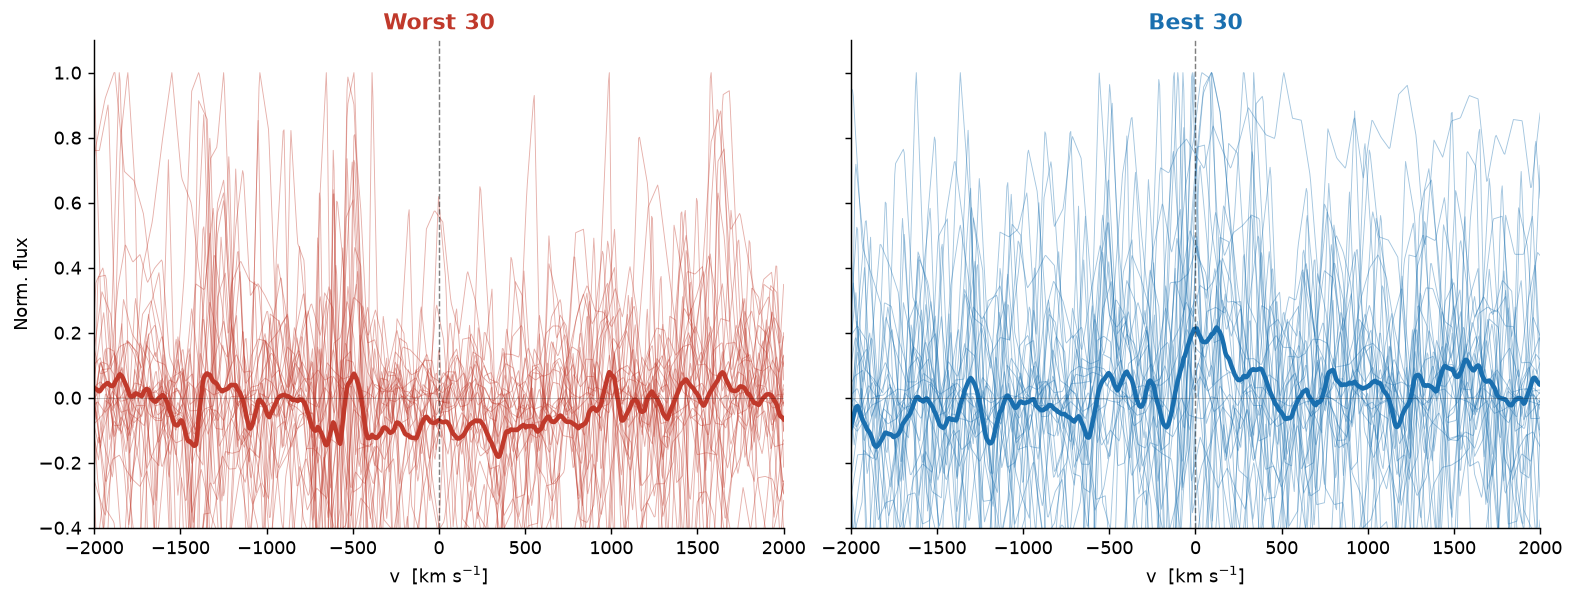

Saved → kmos_best_worst_spectra.pdf / .png


In [ ]:

# ── Overview figure: Best 30 / Worst 30 ─────────────────────────────────────

worst_30 = records_valid[:N_WORST]
best_30  = records_valid[-N_BEST:]

fig, (ax_b, ax_w) = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True,
                                  constrained_layout=True)

for ax, group, color, label in [
    (ax_b, worst_30, "#c0392b", f"Worst {N_WORST}"),
    (ax_w, best_30,  "#1a6faf", f"Best {N_BEST}"),
]:
    fluxes = np.array([r["flux_norm"] for r in group])

    for row in group:
        ax.plot(VEL_GRID, row["flux_norm"], lw=0.5, color=color, alpha=0.40)

    med = np.nanmean(fluxes, axis=0)
    ax.plot(VEL_GRID, med, lw=2.5, color=color)

    ax.axvline(0, color="k", lw=0.8, ls="--", alpha=0.5)
    ax.axhline(0, color="k", lw=0.4, alpha=0.3)
    ax.set_xlim(-VEL_RANGE, VEL_RANGE)
    ax.set_xlabel("v  [km s$^{-1}$]")
    ax.set_title(label, color=color, fontweight="bold")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

ax_b.set_ylabel("Norm. flux")
ax_b.set_ylim(-0.4, 1.1)

plt.savefig("kmos_best_worst_spectra.pdf", bbox_inches="tight")
plt.savefig("kmos_best_worst_spectra.png", bbox_inches="tight", dpi=150)
plt.show()
print("Saved → kmos_best_worst_spectra.pdf / .png")


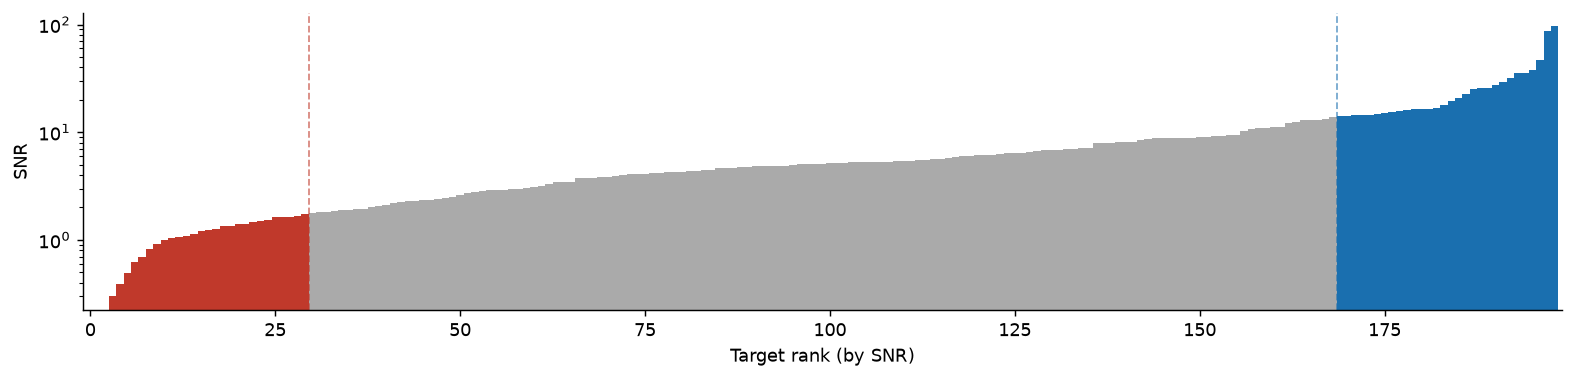

n=199  worst-30 threshold: SNR≤1.7  best-30 threshold: SNR≥14.0


In [ ]:

# ── SNR overview: all targets ranked ─────────────────────────────────────────

snrs_sorted = [r["snr"] for r in records_valid]   # already sorted ascending
n = len(snrs_sorted)
ranks = np.arange(n)
colors = ["#c0392b" if i < N_WORST else
          "#1a6faf" if i >= n - N_BEST else
          "#aaaaaa"
          for i in ranks]

fig2, ax = plt.subplots(figsize=(12, 2.8), constrained_layout=True)
ax.bar(ranks, snrs_sorted, width=1.0, color=colors, linewidth=0)
ax.axhline(0, color="k", lw=0.5, alpha=0.4)
ax.set_xlim(-1, n)
ax.set_xlabel("Target rank (by SNR)")
ax.set_ylabel("SNR")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_yscale('log')

# Threshold lines
ax.axvline(N_WORST - 0.5,     color="#c0392b", lw=1.0, ls="--", alpha=0.6)
ax.axvline(n - N_BEST - 0.5,  color="#1a6faf", lw=1.0, ls="--", alpha=0.6)

plt.savefig("kmos_snr_ranking.pdf", bbox_inches="tight")
plt.savefig("kmos_snr_ranking.png", bbox_inches="tight", dpi=150)
plt.show()
print(f"n={n}  worst-30 threshold: SNR≤{snrs_sorted[N_WORST-1]:.1f}  "
      f"best-30 threshold: SNR≥{snrs_sorted[n-N_BEST]:.1f}")


In [ ]:
# ── Quick table: Best 30 and Worst 30 ────────────────────────────────────────
print("=== BEST 30 ===")
print(f"{'SNR':>7}  {'band':4}  {'line':5}  {'z':6}  {'field':12}  stem")
for r in reversed(best_30):
    print(f"{r['snr']:7.1f}  {r['band']:4}  {r['line']:5}  {r['z']:.4f}  "
          f"{r['field']:12}  {r['stem']}")

print()
print("=== WORST 30 ===")
print(f"{'SNR':>7}  {'band':4}  {'line':5}  {'z':6}  {'field':12}  stem")
for r in worst_30:
    print(f"{r['snr']:7.1f}  {r['band']:4}  {r['line']:5}  {r['z']:.4f}  "
          f"{r['field']:12}  {r['stem']}")

=== BEST 30 ===
    SNR  band  line   z       field         stem
   96.2  IZ    OIII   0.7244  cosmos_0.6_0.8_h21.4.cat  cosmos_0.6_0.8_h21.4.cat_1192752
   86.6  IZ    OIII   0.6560  cdfs_targets_2.cat  cdfs_targets_2.cat_25089
   46.7  IZ    OIII   0.6794  cosmos_0.6_0.8_h21.7.cat  cosmos_0.6_0.8_h21.7.cat_989222
   37.9  IZ    OIII   0.7610  goods_0.6_0.8_h21.6_lir.cat  goods_0.6_0.8_h21.6_lir.cat_4433
   35.4  IZ    OIII   0.7680  goods_0.6_0.8_h21.6_lir.cat  goods_0.6_0.8_h21.6_lir.cat_7781
   35.3  IZ    OIII   0.6710  goods_0.6_0.8_h21.6_lir.cat  goods_0.6_0.8_h21.6_lir.cat_10368
   32.0  IZ    OIII   0.7161  cosmos_target_legac.cat  cosmos_target_legac.cat_3613
   29.0  IZ    OIII   0.6570  goods_0.6_0.8_h21.6_lir.cat  goods_0.6_0.8_h21.6_lir.cat_6308
   27.2  IZ    OIII   0.6864  cosmos_0.6_0.8_h21.7.cat  cosmos_0.6_0.8_h21.7.cat_998074
   25.9  IZ    OIII   0.6830  goods_0.6_0.8_h21.6_lir.cat  goods_0.6_0.8_h21.6_lir.cat_6467
   25.7  YJ    OIII   1.4570  XMM2215_EMPOWER.cat 